# Figure S1C — OFT speed distributions

The left panel shows the distributions of 10-second speed bins after removing the upper 1% within each genotype. The right panel shows the distribution of mean speed across mice.

**Input:** `data/source_data/figure_s01/speeds.xlsx`

**Output:** `results/figures/Fig_S1C.png`

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utilities import ensure_directory, project_path, save_figure

OUTPUT_DIR = ensure_directory(project_path("results", "figures", root=REPO_ROOT))

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
BIN_SECONDS = 10
HISTOGRAM_QUANTILE = 0.99
N_HISTOGRAM_BINS = 50

WT_MOUSE_IDS = [
    "NC128_WT", "NC139_WT", "NC158_WT", "NC166_WT",
    "NC228_WT", "NC230_WT", "NC238_WT", "NC297_WT",
    "NC298_WT", "NC308_WT", "NC314_WT", "NC315_WT",
    "NC324_WT", "NC326_WT", "NC463_WT", "NC476_WT",
]
RTT_MOUSE_IDS = [
    "NC102_RTT", "NC103_RTT", "NC114_RTT", "NC149_RTT",
    "NC159_RTT", "NC227_RTT", "NC232_RTT", "NC239_RTT",
    "NC296_RTT", "NC303_RTT", "NC304_RTT", "NC313_RTT",
    "NC462_RTT", "NC464_RTT", "NC468_RTT", "NC475_RTT",
]

speed_path = project_path(
    "data", "source_data", "figure_s01", "speeds.xlsx", root=REPO_ROOT
)
speeds = pd.read_excel(speed_path, index_col=0)

required = {"WT", "RTT"}
if missing := required.difference(speeds.columns):
    raise ValueError(f"Missing speed columns: {sorted(missing)}")
speeds = speeds.loc[:, ["WT", "RTT"]].apply(pd.to_numeric, errors="coerce")

speeds.describe()

,WT,RTT
count,960.000000,960.000000
mean,44.911979,38.360347
std,29.290674,32.238110
min,1.524264,0.400000
25%,18.497609,8.170015
50%,42.471769,34.841499
75%,64.258172,59.042610
max,222.967505,251.666414


In [4]:
def summarize_mouse_means(values, mouse_ids, genotype):
    values = values.dropna().to_numpy(dtype=float)
    n_mice = len(mouse_ids)
    if len(values) % n_mice != 0:
        raise ValueError(
            f"{genotype} has {len(values)} speed bins, which cannot be divided "
            f"evenly among {n_mice} mice."
        )
    bins_per_mouse = len(values) // n_mice
    return pd.DataFrame({
        "mouse_id": mouse_ids,
        "genotype": genotype,
        "mean_speed": values.reshape(n_mice, bins_per_mouse).mean(axis=1),
        "n_10s_bins": bins_per_mouse,
    })

wt_mouse_speeds = summarize_mouse_means(speeds["WT"], WT_MOUSE_IDS, "WT")
rtt_mouse_speeds = summarize_mouse_means(speeds["RTT"], RTT_MOUSE_IDS, "RTT")
mouse_speeds = pd.concat([wt_mouse_speeds, rtt_mouse_speeds], ignore_index=True)

wt_means = wt_mouse_speeds["mean_speed"].to_numpy()
rtt_means = rtt_mouse_speeds["mean_speed"].to_numpy()
ks_result = ks_2samp(wt_means, rtt_means)

print(
    f"Histogram: {BIN_SECONDS}-s bins; WT n={speeds['WT'].notna().sum()}, "
    f"RTT n={speeds['RTT'].notna().sum()} bins"
)
print(f"Violin plot: WT N={len(wt_means)}, RTT N={len(rtt_means)} mice")
print(f"Two-sample KS test on mouse means: D={ks_result.statistic:.4f}, p={ks_result.pvalue:.4f}")


Histogram: 10-s bins; WT n=960, RTT n=960 bins
Violin plot: WT N=16, RTT N=16 mice
Two-sample KS test on mouse means: D=0.3750, p=0.2145


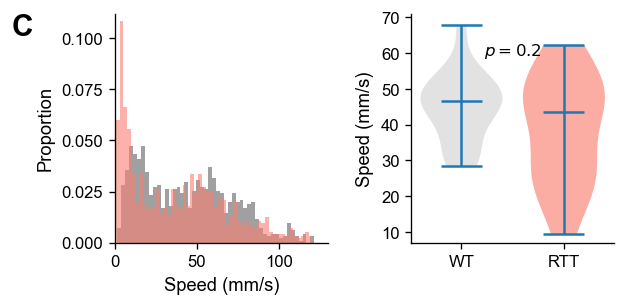

/Users/xiaoqiansun/Desktop/CellReports/results/figures/Fig_S1C.png


In [5]:
# Match the published histogram: remove the upper 1% separately in each genotype.
wt_hist = speeds.loc[
    speeds["WT"] < speeds["WT"].quantile(HISTOGRAM_QUANTILE), "WT"
].dropna().to_numpy()
rtt_hist = speeds.loc[
    speeds["RTT"] < speeds["RTT"].quantile(HISTOGRAM_QUANTILE), "RTT"
].dropna().to_numpy()

fig, (ax_hist, ax_violin) = plt.subplots(
    1, 2, figsize=(5.2, 2.65), gridspec_kw={"width_ratios": [1.05, 1]}
)

ax_hist.hist(
    wt_hist,
    bins=N_HISTOGRAM_BINS,
    weights=np.ones_like(wt_hist) / len(wt_hist),
    color="grey",
    alpha=0.75,
)
ax_hist.hist(
    rtt_hist,
    bins=N_HISTOGRAM_BINS,
    weights=np.ones_like(rtt_hist) / len(rtt_hist),
    color="salmon",
    alpha=0.60,
)
ax_hist.set_xlabel("Speed (mm/s)")
ax_hist.set_ylabel("Proportion")
ax_hist.set_xlim(0, 130)
ax_hist.set_ylim(0, 0.112)
ax_hist.set_yticks([0, 0.025, 0.050, 0.075, 0.100])

parts = ax_violin.violinplot([wt_means, rtt_means], showmedians=True, widths=0.80)
for body, color in zip(parts["bodies"], ["lightgrey", "salmon"]):
    body.set_facecolor(color)
    body.set_edgecolor("none")
    body.set_alpha(0.65)
ax_violin.set_xticks([1, 2], labels=["WT", "RTT"])
ax_violin.set_ylabel("Speed (mm/s)")
ax_violin.set_ylim(7, 71)
ax_violin.set_yticks([10, 20, 30, 40, 50, 60, 70])
ax_violin.text(0.50, 0.82, rf"$p = {ks_result.pvalue:.1f}$", transform=ax_violin.transAxes, ha="center")

fig.text(0.015, 0.94, "C", fontsize=18, fontweight="bold", va="top")
fig.subplots_adjust(left=0.18, right=0.98, bottom=0.22, top=0.94, wspace=0.40)

output_path = save_figure(fig, OUTPUT_DIR / "Fig_S1C.png")
plt.show()
print(output_path)